## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

In [ ]:
import pandas as pd
data = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df = data.copy()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [ ]:
df

In [2]:
df.shape

(2443651, 9)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [4]:
round(df.describe().T, 2)

,count,mean,std,min,25%,50%,75%,max
uid,2443651.0,1370545.35,816056.17,1.0,658921.50,1349029.00,2060685.50,2828593.0
stars,2443651.0,2.15,2.19,0.0,0.00,0.00,4.40,5.0
reviews,2443651.0,480.63,5944.12,0.0,0.00,0.00,59.00,1356658.0
price,2443651.0,89.24,345.61,0.0,9.99,19.09,45.99,100000.0
boughtInLastMonth,2443651.0,25.90,240.48,0.0,0.00,0.00,0.00,50000.0


In [5]:
# General Selection
cat = df.select_dtypes(exclude="number")
num = df.select_dtypes(include="number")

In [6]:
cat.columns

Index(['asin', 'title', 'isBestSeller', 'category'], dtype='object')

In [7]:
cat.asin.unique()

array(['B09B96TG33', 'B01HTH3C8S', 'B09B8YWXDF', ..., 'B0BD5FL5FB',
       'B008OYLL4I', 'B08P3W9B3T'], dtype=object)

In [8]:
cat.head(4)

,asin,title,isBestSeller,category
0,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",False,Hi-Fi Speakers
1,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",True,Hi-Fi Speakers
2,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",False,Hi-Fi Speakers
3,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",False,Hi-Fi Speakers


Crosstab Analysis:

Create a crosstab between the product category and the isBestSeller status.

Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

In [9]:
crosstab_result2 = pd.crosstab(cat['isBestSeller'], cat['category'])
crosstab_result2

category,3D Printers,3D Printing & Scanning,Abrasive & Finishing Products,Action Cameras,Adapters,Agricultural Equipment & Supplies,Alexa Built-In Devices,Art & Craft Supplies,Arts & Crafts,Baby,...,Uninterruptible Power Supply Units & Accessories,Vacuums & Floorcare,Vases,"Water Coolers, Filters & Cartridges",Wearable Technology,Wind Instruments,Window Treatments,Women,Women's Sports & Outdoor Shoes,eBook Readers & Accessories
isBestSeller,,,,,,,,,,,,,,,,,,,,,
False,247,4065,245,1696,251,8421,106,253,9319,14709,...,3652,6919,250,186,8876,243,234,17559,1939,246
True,1,2,5,1,3,109,1,5,230,341,...,1,26,0,1,30,7,5,213,20,0


In [10]:
proportion = (
    df.groupby('category')['isBestSeller']
      .mean()
      .sort_values(ascending=False)
      .reset_index()   # 👈 convierte el índice en columna
)

# Ahora sí puedes usar el nombre 'isBestSeller'
proportion['isBestSeller'] = proportion['isBestSeller'] * 100

top_proportion = proportion.head(10)
top_proportion


,category,isBestSeller
0,Grocery,5.813467
1,Smart Home Security & Lighting,5.769231
2,Health & Personal Care,5.768628
3,Mobile Phone Accessories,4.247104
4,Power & Hand Tools,3.533895
5,"Billiard, Snooker & Pool",3.212851
6,Pet Supplies,3.020028
7,Home Brewing & Wine Making,2.845528
8,Wind Instruments,2.800000
9,Mirrors,2.800000


Statistical Tests:

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
Compute Cramér's V to understand the strength of association between best-seller status and category.

In [11]:
from scipy.stats import chi2_contingency

In [12]:
crosstab_result2

category,3D Printers,3D Printing & Scanning,Abrasive & Finishing Products,Action Cameras,Adapters,Agricultural Equipment & Supplies,Alexa Built-In Devices,Art & Craft Supplies,Arts & Crafts,Baby,...,Uninterruptible Power Supply Units & Accessories,Vacuums & Floorcare,Vases,"Water Coolers, Filters & Cartridges",Wearable Technology,Wind Instruments,Window Treatments,Women,Women's Sports & Outdoor Shoes,eBook Readers & Accessories
isBestSeller,,,,,,,,,,,,,,,,,,,,,
False,247,4065,245,1696,251,8421,106,253,9319,14709,...,3652,6919,250,186,8876,243,234,17559,1939,246
True,1,2,5,1,3,109,1,5,230,341,...,1,26,0,1,30,7,5,213,20,0


In [13]:
_, chi2_pvalue, _, _  = chi2_contingency(crosstab_result2)

In [14]:
a,b,c,d=chi2_contingency(crosstab_result2)

In [15]:
type(chi2_pvalue)

numpy.float64

In [16]:
float(chi2_pvalue) < 0.05

True

In [17]:
from scipy.stats.contingency import association

In [18]:
# Computing the association between variables in 'crosstab_result' using the "cramer" method
association(crosstab_result2, method='cramer')

0.1222829439760564

Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

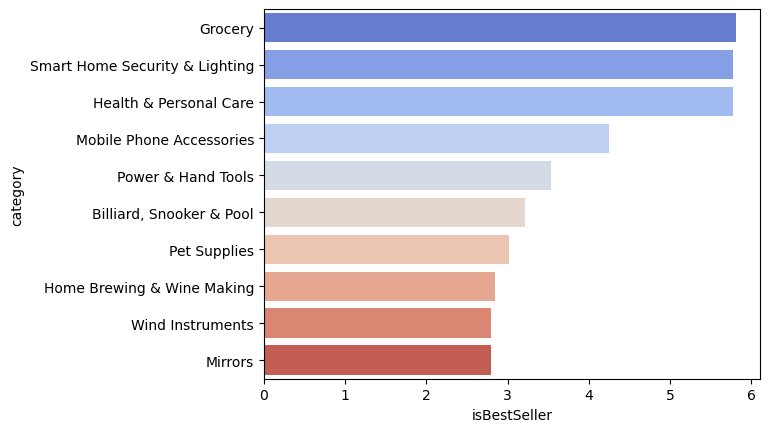

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.barplot(data=top_proportion, x="isBestSeller", y="category",
            hue="category", palette="coolwarm", legend=False, errorbar=None)
plt.show()

## Part 2: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.

Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

Violin Plots:

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
Which product category tends to have the highest median price? Don't filter here by top categories.
Bar Charts:

Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories.
Box Plots:

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [20]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
uid,2443651.0,1.370545e+06,816056.169852,1.0,658921.50,1349029.00,2060685.50,2828593.0
stars,2443651.0,2.152836e+00,2.194865,0.0,0.00,0.00,4.40,5.0
reviews,2443651.0,4.806278e+02,5944.124151,0.0,0.00,0.00,59.00,1356658.0
price,2443651.0,8.924381e+01,345.608862,0.0,9.99,19.09,45.99,100000.0
boughtInLastMonth,2443651.0,2.589699e+01,240.483727,0.0,0.00,0.00,0.00,50000.0


In [21]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_no_outliers = df[(df['price'] >= lower) & (df['price'] <= upper)]

In [22]:
df_no_outliers

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


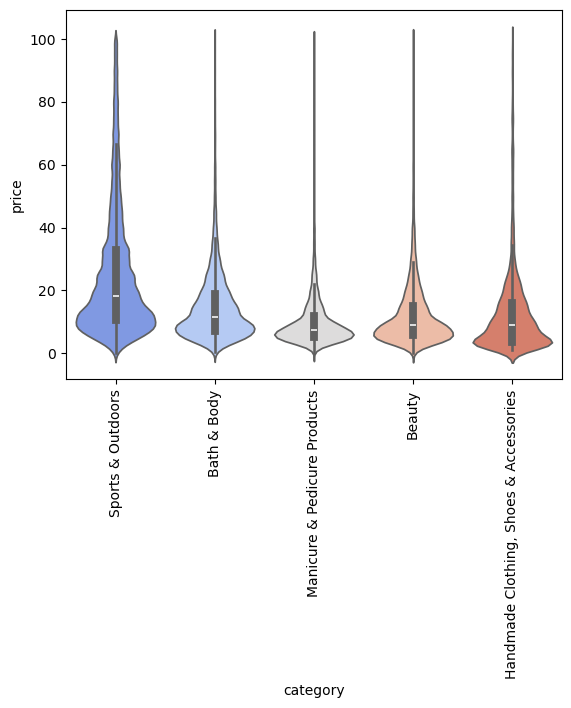

In [23]:
top20 = df_no_outliers['category'].value_counts().head(5).index
sns.violinplot(data=df_no_outliers[df_no_outliers['category'].isin(top20)],
               x='category', y='price', hue="category", palette="coolwarm", legend=False)
plt.xticks(rotation=90)
plt.show()


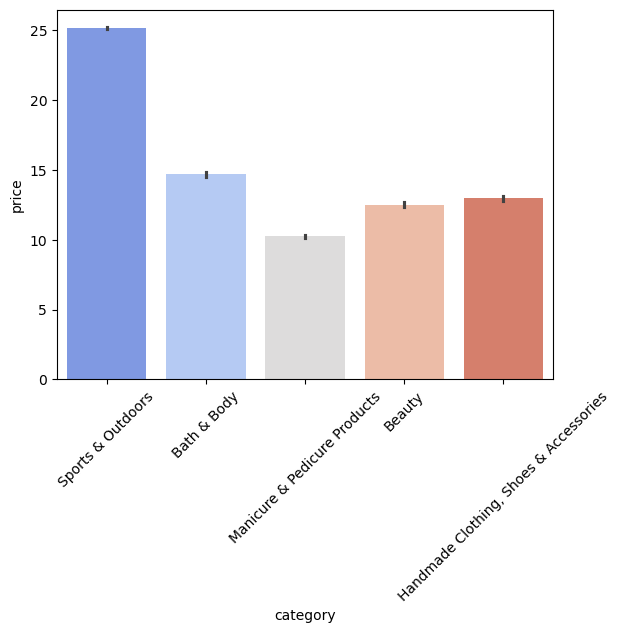

In [24]:
top5 = df_no_outliers['category'].value_counts().head(5).index
sns.barplot(data=df_no_outliers[df_no_outliers['category'].isin(top5)],
            x='category', y='price', hue="category", palette="coolwarm", legend=False)
plt.xticks(rotation=45)
plt.show()


In [25]:
df_no_outliers.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

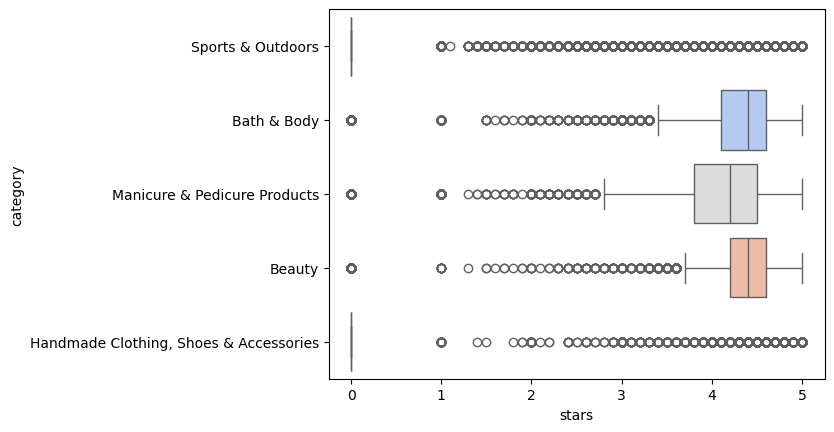

In [26]:
top5 = df_no_outliers['category'].value_counts().head(5).index
sns.boxplot(data=df_no_outliers[df_no_outliers['category'].isin(top5)],
            x='stars', y='category', hue="category", palette="coolwarm", legend=False)
plt.show()

## Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?
Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.
Submission: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings.

Bonus:

Do the same analysis without taking out the outliers. What are your insights?

In [27]:
round(float(df["stars"].corr(df["price"], method="pearson")), 2)

-0.12

In [28]:
df["stars"].corr(df["price"], method="spearman")

np.float64(-0.13316425462433998)

In [29]:
round(float(df["stars"].corr(df["price"], method="spearman")), 2)

-0.13

In [30]:
num.corrwith(num["price"], method="spearman").sort_values(ascending=False)

price                1.000000
uid                 -0.008249
stars               -0.133164
reviews             -0.148690
boughtInLastMonth   -0.198937
dtype: float64

In [31]:
num.corr()

,uid,stars,reviews,price,boughtInLastMonth
uid,1.000000,0.031696,0.019994,0.008273,0.016336
stars,0.031696,1.000000,0.085808,-0.124907,0.112536
reviews,0.019994,0.085808,1.000000,-0.013171,0.104043
price,0.008273,-0.124907,-0.013171,1.000000,-0.023439
boughtInLastMonth,0.016336,0.112536,0.104043,-0.023439,1.000000


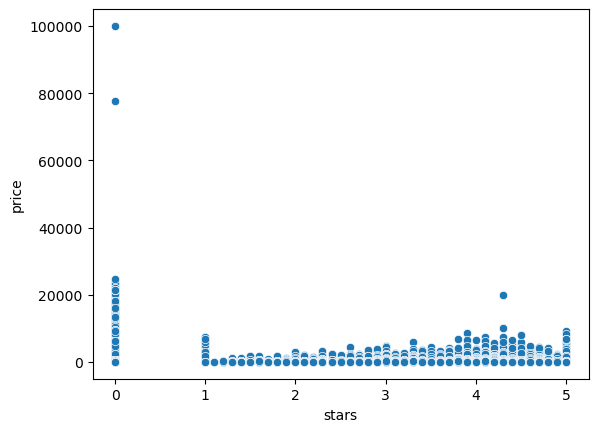

In [32]:
sns.scatterplot(data=df, x='stars', y='price')
plt.show()

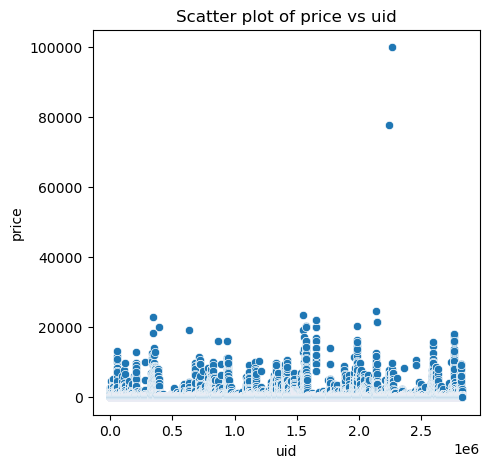

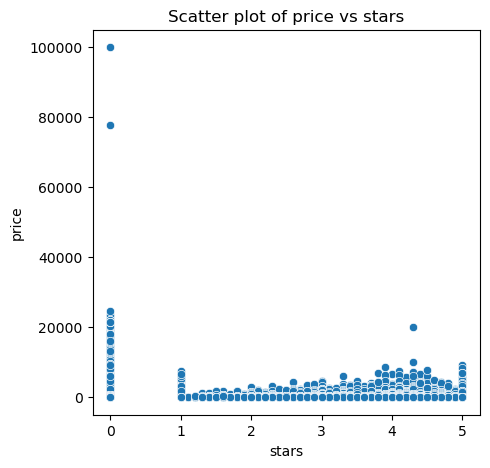

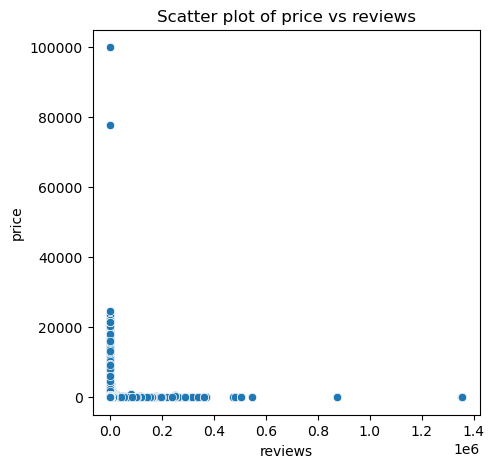

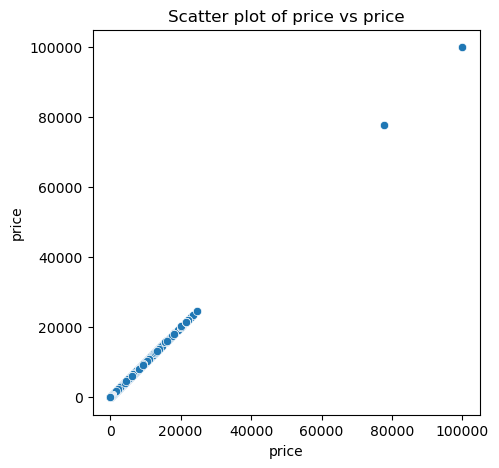

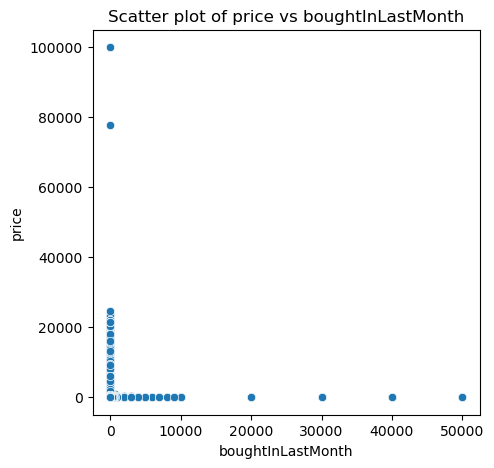

In [36]:
for col in num.columns:
    plt.figure(figsize=(5, 5))
    plt.title('Scatter plot of price vs ' + col)
    sns.scatterplot(data=df, x=col, y='price')
    plt.show()

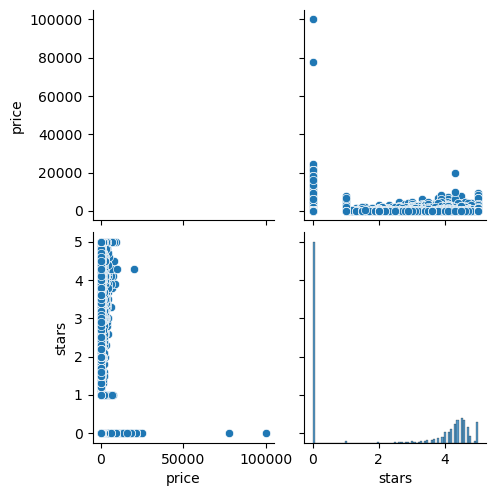

In [35]:
sns.pairplot(df[["price", "stars"]])
plt.show()

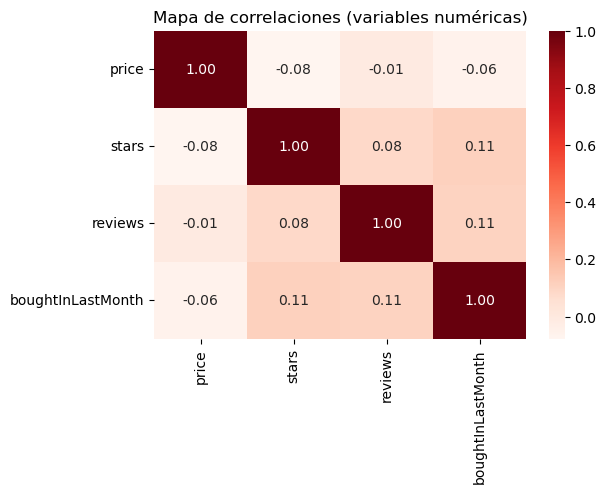

In [42]:
plt.figure(figsize=(6,4))
sns.heatmap(
    df_no_outliers[['price', 'stars', 'reviews', 'boughtInLastMonth']].corr(),
    annot=True, 
    cmap='Reds', 
    fmt=".2f"       # ✅ Mostrar decimales correctamente
)
plt.title('Mapa de correlaciones (variables numéricas)')
plt.show()

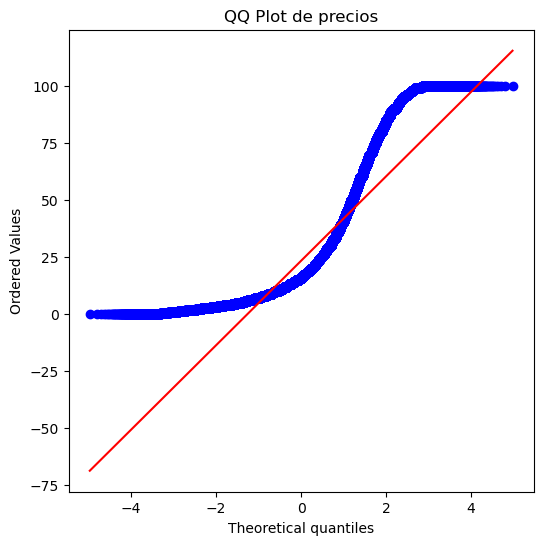

In [38]:
import scipy.stats as stats
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
stats.probplot(df_no_outliers['price'], dist="norm", plot=plt)
plt.title('QQ Plot de precios')
plt.show()

In [43]:
corr_all = df['price'].corr(df['stars'])
print("Correlación SIN eliminar outliers:", round(corr_all, 3))

Correlación SIN eliminar outliers: -0.125
